# import libraries

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# load data

In [2]:
df = pd.read_csv("data/hour.csv" ,parse_dates=["dteday"])
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# EDA

In [3]:
len(df)

17379

In [4]:
df.info() # no null

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 17379 entries, 0 to 17378
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   instant     17379 non-null  int64         
 1   dteday      17379 non-null  datetime64[ns]
 2   season      17379 non-null  int64         
 3   yr          17379 non-null  int64         
 4   mnth        17379 non-null  int64         
 5   hr          17379 non-null  int64         
 6   holiday     17379 non-null  int64         
 7   weekday     17379 non-null  int64         
 8   workingday  17379 non-null  int64         
 9   weathersit  17379 non-null  int64         
 10  temp        17379 non-null  float64       
 11  atemp       17379 non-null  float64       
 12  hum         17379 non-null  float64       
 13  windspeed   17379 non-null  float64       
 14  casual      17379 non-null  int64         
 15  registered  17379 non-null  int64         
 16  cnt         17379 non-

## 1. Data quality

In [5]:
display(df.describe().T)
print("duplicates:", df.duplicated().sum())

# hour.csv skips hours with zero rentals
expected = (df.dteday.max() - df.dteday.min()).days * 24 + 24
print("rows:", len(df), "| expected hourly rows:", expected, "| missing hours:", expected - len(df))

print("casual + registered == cnt:", (df.casual + df.registered == df.cnt).all())
print("windspeed == 0 share:", (df.windspeed == 0).mean().round(3))
print(df.weathersit.value_counts().sort_index())

,count,mean,min,25%,50%,75%,max,std
instant,17379.0,8690.0,1.0,4345.5,8690.0,13034.5,17379.0,5017.0295
dteday,17379,2012-01-02 04:08:34.552045568,2011-01-01 00:00:00,2011-07-04 00:00:00,2012-01-02 00:00:00,2012-07-02 00:00:00,2012-12-31 00:00:00,NaN
season,17379.0,2.50164,1.0,2.0,3.0,3.0,4.0,1.106918
yr,17379.0,0.502561,0.0,0.0,1.0,1.0,1.0,0.500008
mnth,17379.0,6.537775,1.0,4.0,7.0,10.0,12.0,3.438776
hr,17379.0,11.546752,0.0,6.0,12.0,18.0,23.0,6.914405
holiday,17379.0,0.02877,0.0,0.0,0.0,0.0,1.0,0.167165
weekday,17379.0,3.003683,0.0,1.0,3.0,5.0,6.0,2.005771
workingday,17379.0,0.682721,0.0,0.0,1.0,1.0,1.0,0.465431
weathersit,17379.0,1.425283,1.0,1.0,1.0,2.0,4.0,0.639357


duplicates: 0
rows: 17379 | expected hourly rows: 17544 | missing hours: 165
casual + registered == cnt: True
windspeed == 0 share: 0.125
weathersit
1    11413
2     4544
3     1419
4        3
Name: count, dtype: int64


### ✅ Answer: is the data clean?
- 17,379 rows, no nulls, no duplicates; `casual + registered = cnt` holds for every row.
- 165 hours are missing out of 17,544 (under 1%). `hour.csv` only records hours with at least one rental, so these are quiet night hours, not errors.
- 12.5% of rows have `windspeed = 0`. This is probably missing or coarse wind data stored as zero, so treat wind with caution.
- Weather category 4 (heavy rain/snow) has only **3 rows**, so its averages are unreliable. Merge it with category 3 when modelling.

## 2. Readable labels and real units

In [6]:
season_map = {1: "winter", 2: "spring", 3: "summer", 4: "fall"}
df["season_name"] = df.season.map(season_map)
df["year"] = df.yr.map({0: 2011, 1: 2012})
df["day_type"] = df.workingday.map({0: "non-working", 1: "working"})

df["temp_c"] = df.temp * (39 - (-8)) + (-8)
df["atemp_c"] = df.atemp * (50 - (-16)) + (-16)
df["hum_pct"] = df.hum * 100
df["wind_raw"] = df.windspeed * 67

## 3. Target distribution

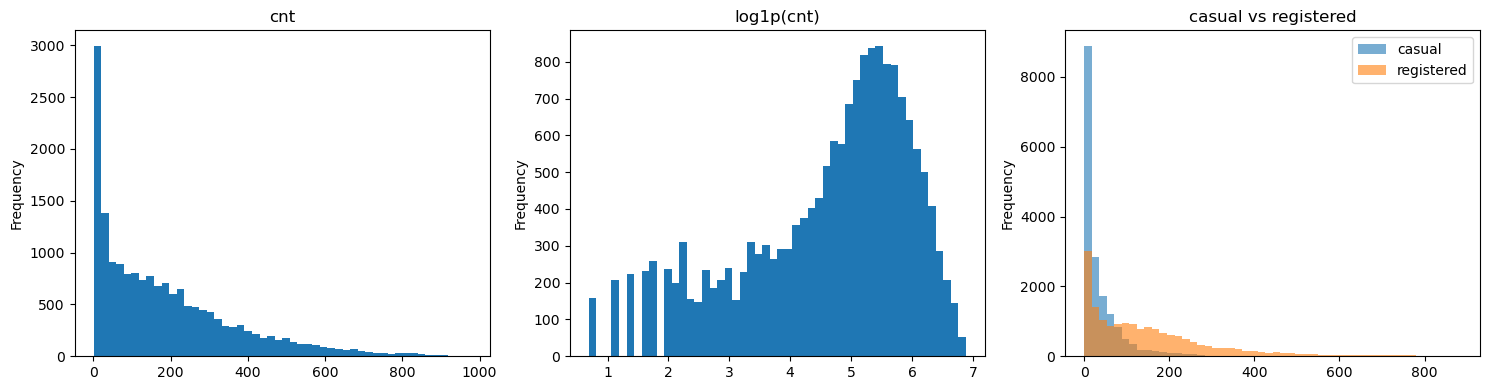

skew: 1.28


In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.cnt.plot.hist(bins=50, ax=ax[0], title="cnt")
np.log1p(df.cnt).plot.hist(bins=50, ax=ax[1], title="log1p(cnt)")
df[["casual", "registered"]].plot.hist(bins=50, alpha=.6, ax=ax[2], title="casual vs registered")
plt.tight_layout(); plt.show()
print("skew:", round(df.cnt.skew(), 2))

### ✅ Answer: what does the target look like?
Hourly rentals are **right-skewed** (skewness 1.28): many quiet hours and a long tail of very busy ones. A log transform makes the distribution more symmetric and is worth using for modelling.

## 4. Hourly demand pattern

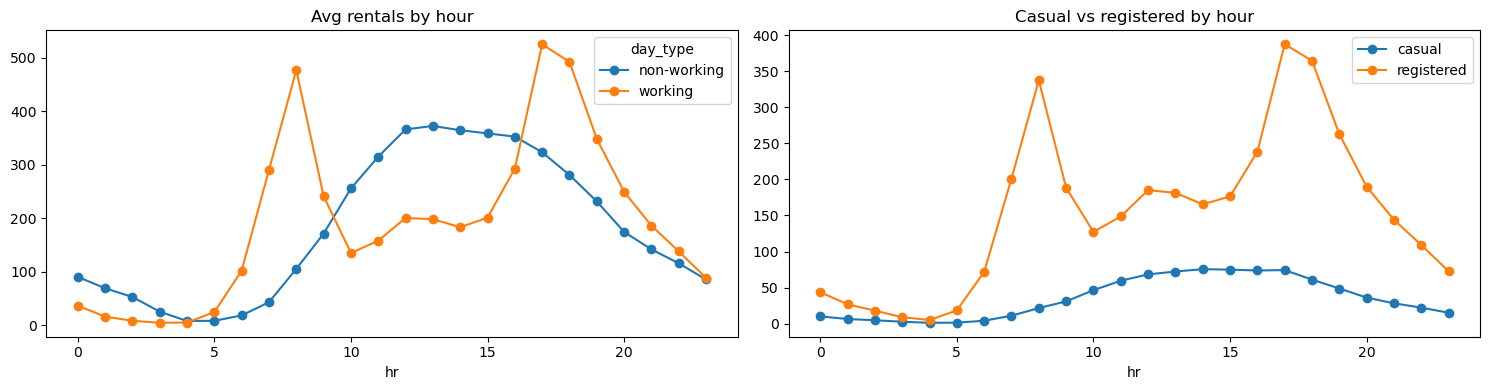

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
df.groupby(["hr", "day_type"]).cnt.mean().unstack().plot(ax=ax[0], marker="o", title="Avg rentals by hour")
df.groupby("hr")[["casual", "registered"]].mean().plot(ax=ax[1], marker="o", title="Casual vs registered by hour")
plt.tight_layout(); plt.show()

### ✅ Answer (Q1 and Q10): when is demand highest, and who rides?
- **Working days have two commute peaks**: about 8:00 (~475 rentals/hour) and 17:00–18:00 (~525 at 17:00). Midday is a lower plateau (~200).
- **Non-working days have one broad hump** from about 11:00 to 16:00 (peak ~370 around 13:00), with no morning rush.
- **Registered users create the commute peaks.** Casual riders are far fewer and follow a flat afternoon curve (max ~75/hour vs ~390 for registered).
- Demand is lowest between 2:00 and 5:00 on all days.

## 5. Trend and seasonality

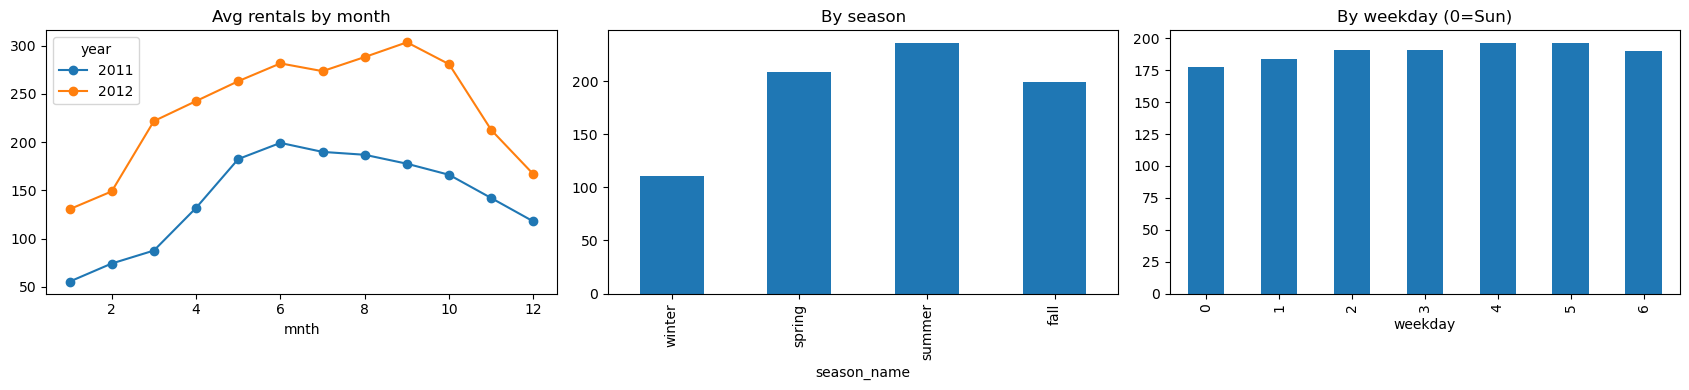

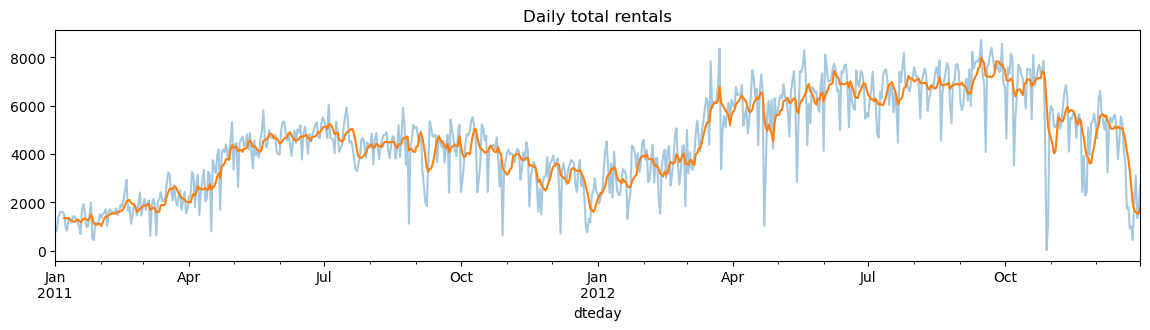

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
df.groupby(["mnth", "year"]).cnt.mean().unstack().plot(ax=ax[0], marker="o", title="Avg rentals by month")
df.groupby("season_name").cnt.mean().reindex(season_map.values()).plot.bar(ax=ax[1], title="By season")
df.groupby("weekday").cnt.mean().plot.bar(ax=ax[2], title="By weekday (0=Sun)")
plt.tight_layout(); plt.show()

daily = df.groupby("dteday").cnt.sum()
ax = daily.plot(figsize=(14, 3), alpha=.4, title="Daily total rentals")
daily.rolling(7).mean().plot(ax=ax)
plt.show()

### ✅ Answer (Q4): how do seasons, months and weekdays affect demand?
- **Season:** summer is busiest (~235 rentals/hour), then spring (~208) and fall (~199). **Winter is about half of summer** (~110).
- **Month:** demand rises from January to a summer/early-autumn peak (June in 2011, September in 2012) and falls toward December.
- **Growth:** every month of 2012 is clearly above the same month of 2011, so there is a strong year-over-year trend on top of seasonality.
- **Weekday:** averages are very similar (about 178 on Sunday to 196 on Thursday/Friday). Weekday changes the *shape* of the day far more than the total.

## 6. Weather effects

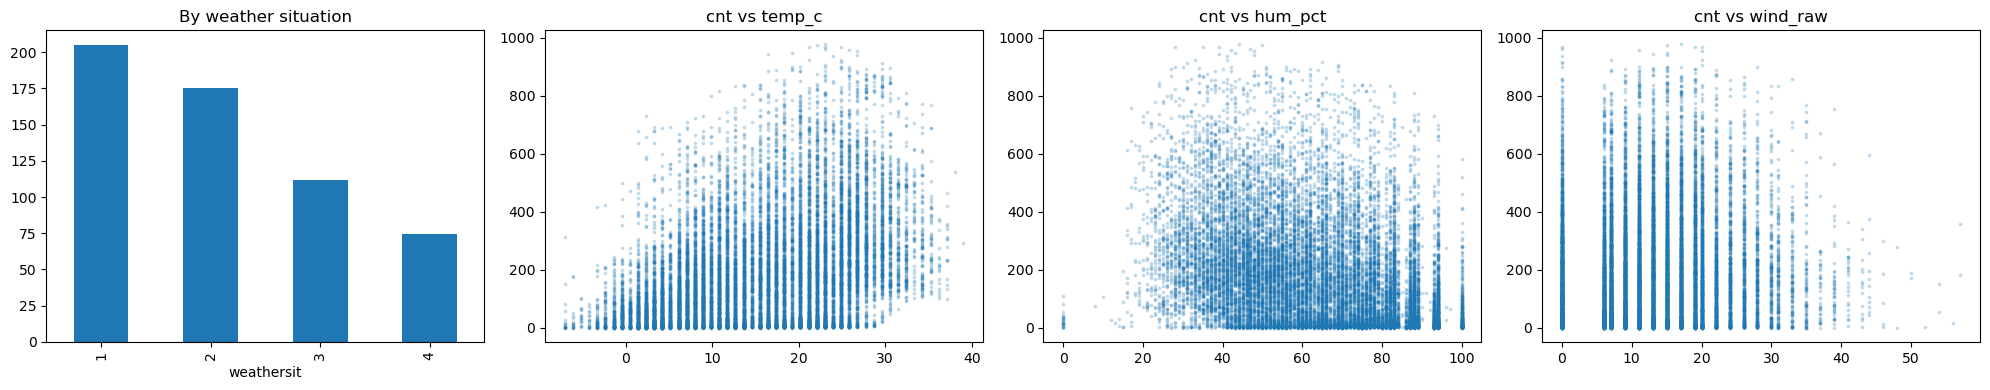

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4))
df.groupby("weathersit").cnt.mean().plot.bar(ax=ax[0], title="By weather situation")
for a, col in zip(ax[1:], ["temp_c", "hum_pct", "wind_raw"]):
    a.scatter(df[col], df.cnt, s=3, alpha=.2)
    a.set_title(f"cnt vs {col}")
plt.tight_layout(); plt.show()

### ✅ Answer (Q7): how much does weather matter?
- **Weather condition:** clear weather averages ~205 rentals/hour, mist/cloudy ~175 and light rain/snow ~112 (about 45% below clear).
- **Temperature:** demand rises steadily with temperature up to roughly 25–30 °C and then flattens or drops in extreme heat. Very few rentals occur below 0 °C.
- **Humidity:** the cloud of points shifts downward at high humidity, so wet, humid hours have fewer rentals.
- **Wind:** the pattern is weak; very high wind has few observations and lower counts.

## 7. Correlations

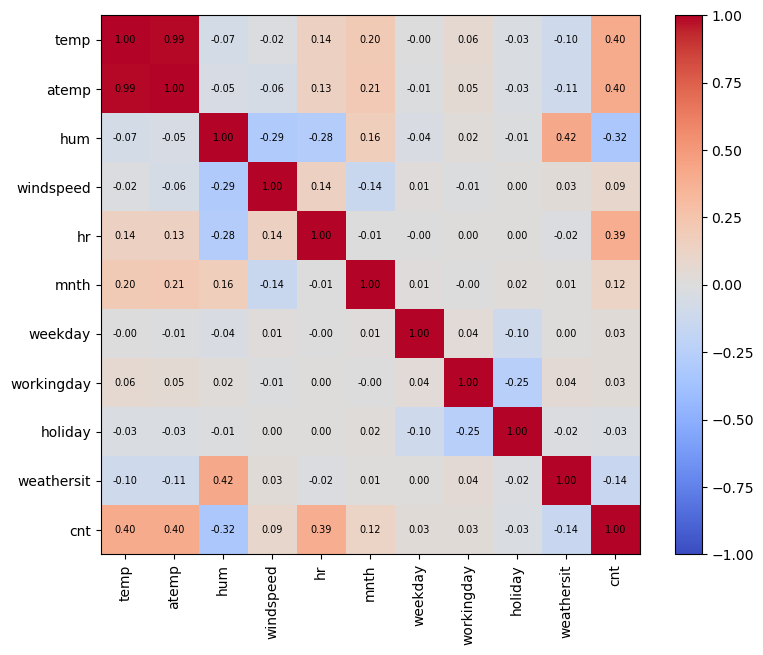

In [11]:
num = ["temp", "atemp", "hum", "windspeed", "hr", "mnth", "weekday", "workingday", "holiday", "weathersit", "cnt"]
corr = df[num].corr()

fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(num)), num, rotation=90)
ax.set_yticks(range(len(num)), num)
for i in range(len(num)):
    for j in range(len(num)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im); plt.show()

## 8. Outliers

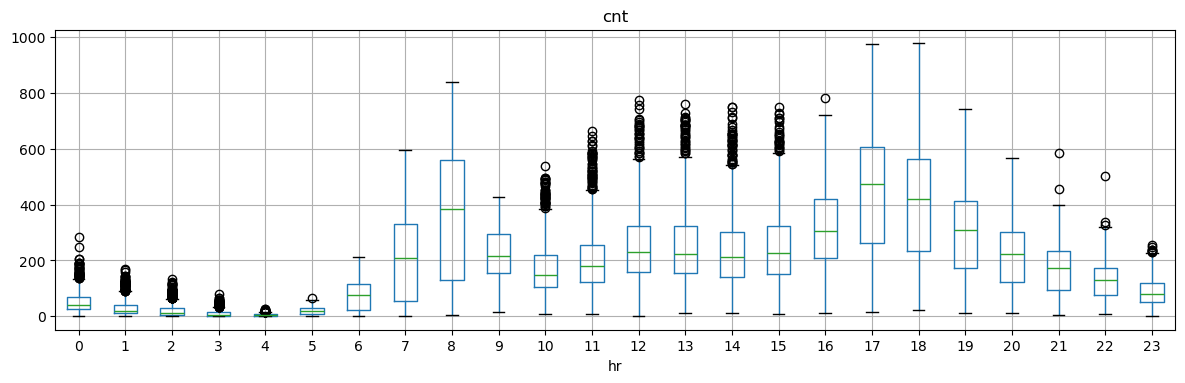

In [12]:
df.boxplot(column="cnt", by="hr", figsize=(14, 4))
plt.suptitle(""); plt.show()

# Additional questions (Q3, Q5, Q6, Q8, Q9, Q11, Q12, Q13)

## Q3. Do public holidays behave like weekends or working days?

day_cat
Holiday        156.9
Weekend        183.9
Working day    193.2
Name: cnt, dtype: float64


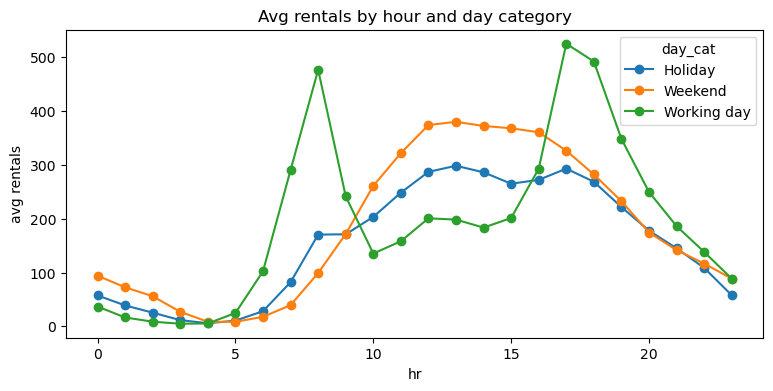

In [13]:
df["day_cat"] = "Weekend"
df.loc[df.workingday == 1, "day_cat"] = "Working day"
df.loc[df.holiday == 1, "day_cat"] = "Holiday"
print(df.groupby("day_cat").cnt.mean().round(1))
df.groupby(["hr", "day_cat"]).cnt.mean().unstack().plot(marker="o", figsize=(9, 4), title="Avg rentals by hour and day category")
plt.ylabel("avg rentals"); plt.show()

### ✅ Answer (Q3): do holidays behave like weekends or working days?
**Like weekends, only quieter.**
- Average rentals per hour: **holidays 157, weekends 184, working days 193**.
- On holidays there are no sharp commute peaks: a single broad midday hump (peak ~300 around 13:00), the same shape as weekends but about 20% lower. A small bump at 8:00 (~170) is the only trace of a morning rush.
- Holidays are only about 21 days in the data, so this estimate is based on few days. Part of the gap may come from several holidays falling in colder months (not tested here).

## Q5. Was growth from 2011 to 2012 the same in every month?

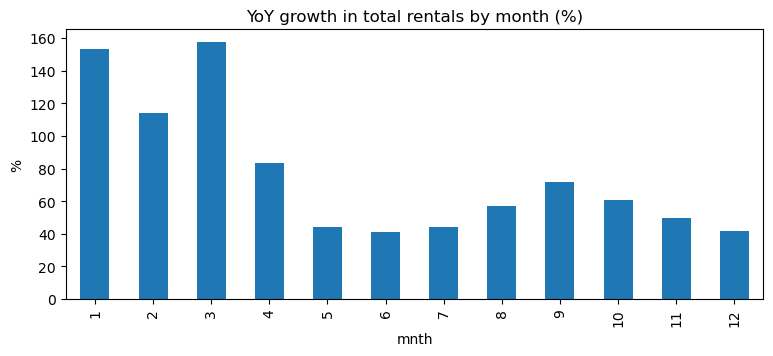

overall growth: 65%


In [14]:
mm = df.pivot_table(index="mnth", columns="year", values="cnt", aggfunc="sum")
growth = (mm[2012] / mm[2011] - 1) * 100
growth.plot.bar(figsize=(9, 3.5), title="YoY growth in total rentals by month (%)")
plt.ylabel("%"); plt.show()
print("overall growth: {:.0%}".format(df[df.year == 2012].cnt.sum() / df[df.year == 2011].cnt.sum() - 1))

### ✅ Answer (Q5): was growth the same in every month?
**No.** Overall rentals grew **65%** from 2011 to 2012, but the growth by month was very uneven:
- **January–March: about +115% to +157%.** The system was still small in early 2011, so the starting point was low.
- **April: about +83%.** From **May to July the growth was only about +41% to +44%**, and December about +42%.
- September (~+72%) and October (~+61%) were in between.

So growth was strongest early in the period and slowed as the system matured; the average hides this.

## Q6. Busiest and quietest days

In [15]:
day = df.groupby("dteday").agg(rentals=("cnt", "sum"), temp_c=("temp_c", "mean"), weather=("weathersit", "max"))
display(day.nlargest(10, "rentals"))
display(day.nsmallest(10, "rentals"))

,rentals,temp_c,weather
dteday,,,
2012-09-15,8714,20.591667,2
2012-09-29,8555,17.497500,2
2012-09-22,8395,22.550000,1
2012-03-23,8362,20.278333,2
2012-05-19,8294,20.200000,1
2012-09-09,8227,20.670000,2
2012-07-25,8173,26.035833,1
2012-09-21,8167,20.160833,1
2012-10-05,8156,20.905000,1


,rentals,temp_c,weather
dteday,,,
2012-10-29,22,12.680000,3
2011-01-27,431,1.165000,1
2012-12-26,441,3.436667,3
2011-01-26,506,2.222500,4
2011-03-06,605,9.696522,3
2011-03-10,623,10.287273,3
2011-10-29,627,3.945833,3
2011-01-18,683,2.183333,2
2011-12-07,705,11.270000,3


### ✅ Answer (Q6): busiest and quietest days
**Busiest days**
- All 10 are in **2012**, with 8,100–8,700 rentals per day. **Five are in September.**
- They are mild, dry days (about 17–26 °C, weather clear or mist), mostly Fridays and Saturdays.

**Quietest days**
- The lowest day is **2012-10-29 with only 22 rentals** (rain or snow). That date is consistent with Hurricane Sandy, though the data itself doesn't say so.
- Most of the others are cold (1–5 °C) or rainy winter days in early 2011; 6 of the 10 have light rain/snow as their worst weather, and one has category 4.
- Holidays also appear: 2011-12-25 (754) and 2012-12-26 (441).
- 8 of the 10 quietest days are in 2011, which is partly the lower starting level of the system.

## Q8. Does bad weather erase the commute peaks or only shrink them?

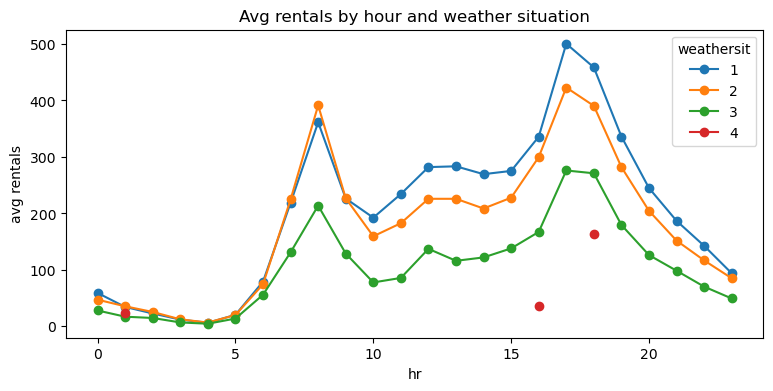

In [16]:
df.groupby(["hr", "weathersit"]).cnt.mean().unstack().plot(marker="o", figsize=(9, 4), title="Avg rentals by hour and weather situation")
plt.ylabel("avg rentals"); plt.show()

### ✅ Answer (Q8): does bad weather erase the commute peaks or only shrink them?
**It shrinks them, it doesn't erase them.**
- In light rain/snow (category 3) the 8:00 and 17:00 peaks are still there, but about **40–45% lower** than in clear weather (for example ~275 vs ~500 at 17:00).
- Mist/cloudy (category 2) is close to clear at commute hours and about 15–20% lower at midday, so commuters mostly still ride.
- Category 4 has only 3 observations, so ignore its points.

## Q9. Which weather variable is most related to demand?

temp_c      0.405
atemp_c     0.401
hum_pct    -0.323
wind_raw    0.093
Name: cnt, dtype: float64


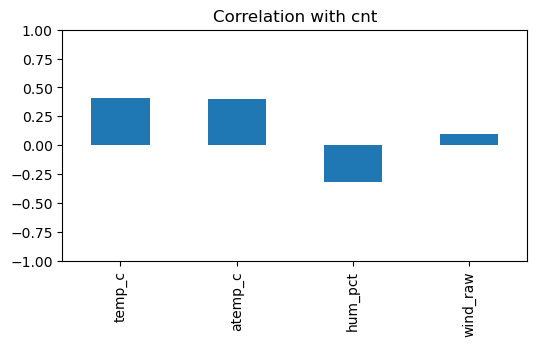

In [17]:
c = df[["temp_c", "atemp_c", "hum_pct", "wind_raw", "cnt"]].corr()["cnt"].drop("cnt")
print(c.round(3))
c.plot.bar(figsize=(6, 3), title="Correlation with cnt"); plt.ylim(-1, 1); plt.show()

### ✅ Answer (Q9): which weather variable matters most?
**Temperature.**
- Correlation with rentals: temperature **+0.41**, feels-like temperature **+0.40**, humidity **−0.32**, wind speed **+0.09**.
- Temperature and feels-like carry nearly the same information; use only one in a linear model.
- Humidity has a negative effect. Wind has almost no linear relationship (and its zeros are suspect).
- These are modest correlations because the hour of day explains a lot of the variation.

## Q11. When do casual riders make up the biggest share?

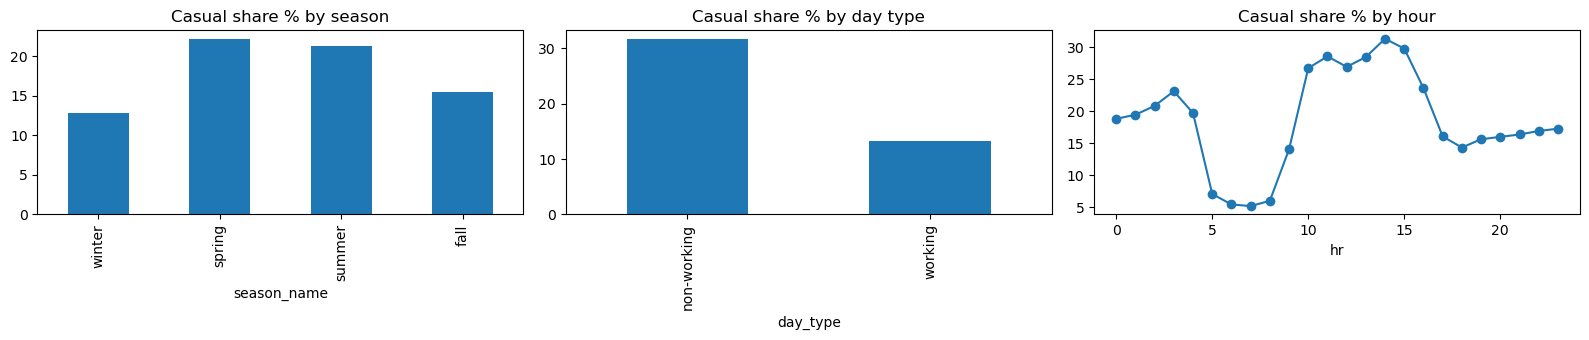

In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 3.5))
(df.groupby("season_name")[["casual", "cnt"]].sum().pipe(lambda x: x.casual / x.cnt * 100)
   .reindex(["winter", "spring", "summer", "fall"]).plot.bar(ax=ax[0], title="Casual share % by season"))
(df.groupby("day_type")[["casual", "cnt"]].sum().pipe(lambda x: x.casual / x.cnt * 100)
   .plot.bar(ax=ax[1], title="Casual share % by day type"))
(df.groupby("hr")[["casual", "cnt"]].sum().pipe(lambda x: x.casual / x.cnt * 100)
   .plot(ax=ax[2], marker="o", title="Casual share % by hour"))
plt.tight_layout(); plt.show()

### ✅ Answer (Q11): when do casual riders make up the biggest share?
- **Day type:** about **32% of rentals are casual on non-working days vs about 13% on working days.**
- **Season:** highest in spring (~22%) and summer (~21%), lower in fall (~15%) and winter (~13%).
- **Hour:** casual share is highest from about 10:00 to 15:00 (up to ~31% at 14:00) and lowest during the commute, at about 5% around 6:00–8:00.
- Casual riders are mostly leisure riders: warm weekend afternoons.

## Q12. Which month and hour combinations are busiest?

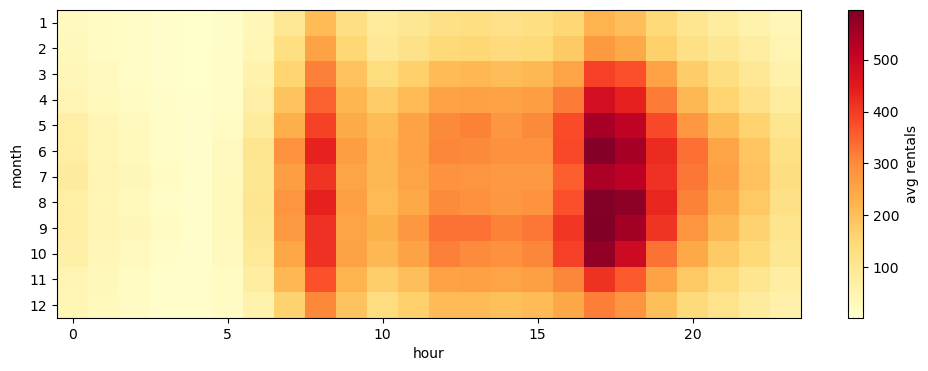

In [19]:
mh = df.pivot_table(index="mnth", columns="hr", values="cnt", aggfunc="mean")
fig, ax = plt.subplots(figsize=(12, 4))
im = ax.imshow(mh, aspect="auto", cmap="YlOrRd")
ax.set_xlabel("hour"); ax.set_ylabel("month"); ax.set_yticks(range(12), range(1, 13))
plt.colorbar(im, label="avg rentals"); plt.show()

### ✅ Answer (Q12): which month and hour combinations are busiest?
- The hottest cells are **17:00–18:00 from May to October** (above ~550 average rentals), with June to September strongest.
- The **8:00 peak** is the second-hottest band in every month.
- In summer months the midday plateau (11:00–15:00) is also much higher than in winter.
- January, February and December are light all day. The hours from 0:00 to 5:00 are quiet in every month.

## Q13. How variable is hourly demand? Outliers

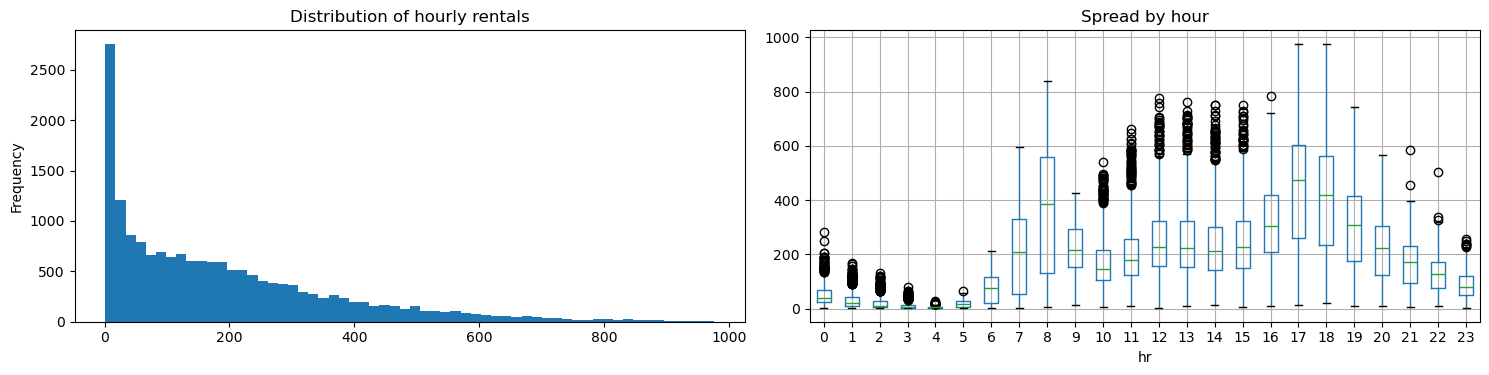

skew: 1.28


In [20]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
df.cnt.plot.hist(bins=60, ax=ax[0], title="Distribution of hourly rentals")
df.boxplot(column="cnt", by="hr", ax=ax[1]); ax[1].set_title("Spread by hour"); plt.suptitle("")
plt.tight_layout(); plt.show()
print("skew:", round(df.cnt.skew(), 2))

### ✅ Answer (Q13): how variable is hourly demand, and where are the outliers?
- The histogram is strongly right-skewed (skew 1.28): about 2,700 hours have almost no rentals and the tail reaches roughly 1,000.
- **Variability is largest at the commute peaks** (8:00 and 17:00–18:00): the box spans roughly 130–560 at 8:00 and 260–600 at 17:00, so the same hour can be quiet or very busy depending on the day (working day, weather, season).
- **Outliers** appear at midday (10:00–15:00) and at night (0:00–3:00). These are unusually busy hours for that time, typically warm weekend days, not data errors.
- Plan operations on the *peak* hours, not only on averages.

# Summary of findings
1. **Commuter system.** Working days show peaks at 8:00 and 17:00–18:00; weekends show one midday hump. Registered riders create the peaks.
2. **Holidays look like weekends but quieter** (157 vs 184 rentals/hour on average).
3. **Strong seasonality.** Summer is busiest; winter is about half of summer. The busiest slot of the year is 17:00–18:00 between May and October.
4. **Strong growth.** Rentals rose 65% from 2011 to 2012, with the largest gains in January–March (+115% to +157%) and the smallest in May–July (about +41–44%).
5. **Weather matters.** Light rain/snow cuts rentals about 45% and shrinks, but does not remove, the commute peaks. Temperature is the weather variable most related to demand (+0.41); humidity is negative (−0.32).
6. **Casual riders are leisure riders.** About 32% of non-working-day rentals vs 13% on working days, and up to ~31% of rentals at 14:00.
7. **Extremes:** the busiest days are mild September/spring days in 2012 (8,100–8,700 rentals); the quietest are storm or cold winter days (as low as 22 rentals).
8. **Data caveats:** weather category 4 has only 3 rows; 12.5% of wind values are zero; `casual`/`registered` must not be used as features for `cnt` (leakage).

**Recommendations:** rebalance and service bikes before 8:00 and 16:00 on working days; schedule maintenance between 0:00 and 5:00; target casual riders with promotions on warm weekend afternoons; reduce fleet deployment on rainy or snowy days.